# Explaining GNN predictions

A trained GNN tells you *what* it predicts for a node, but not *why*. The answer is spread over the node's neighborhood: which neighbors, which edges and which input features pushed the model towards its prediction. **Explainability** methods recover that information as **masks**, an importance score for every edge and/or node (or node feature) of the graph.

`mlx_graphs.explain` provides these methods with the same interface as `torch_geometric.explain`:

- an `Explainer` that wraps a trained model and an explanation algorithm,
- three algorithms: `GNNExplainer` (learns a mask by optimization), `Saliency` (input gradients) and `IntegratedGradients` (gradients averaged along a path),
- an `Explanation` object holding the masks, with methods to threshold and draw them,
- metrics to score explanations: fidelity, the characterization score and, when the true explanation is known, a ground-truth AUC.

This tutorial uses **BA-Shapes**, the synthetic benchmark of the GNNExplainer paper, where the correct explanation of every prediction is known, so we can check that the explainers find it. It then explains a model trained on **Cora**, a real citation graph, to show which input features a prediction relies on.

The plots need matplotlib and networkx, which come with the `viz` extra:

```
pip install "mlx-graphs[viz]"
```

![Explainability pipeline: ba_shapes builds a Barabasi-Albert graph of 300 base nodes with 80 house motifs, whose edges (edge_groundtruth) are the true explanation; a GCN of 3 GCNConv layers that takes edge_weights and a Linear head classifies every node as base, middle, bottom or top; an Explainer runs Saliency, IntegratedGradients or GNNExplainer on one node and returns an Explanation whose edge mask highlights the edges into the explained roof node; explanations are scored with groundtruth_auc, fidelity and the characterization score, thresholded and drawn with visualize_graph; on Cora, a node mask of type attributes gives one score per word, plotted with visualize_feature_importance](../../assets/tutorials/explainability.svg)

In [9]:
import time

import mlx.core as mx
import mlx.nn as nn
import mlx.optimizers as optim
import numpy as np

from mlx_graphs.datasets import PlanetoidDataset
from mlx_graphs.explain import Explainer
from mlx_graphs.explain.algorithm import GNNExplainer, IntegratedGradients, Saliency
from mlx_graphs.explain.datasets import ba_shapes
from mlx_graphs.explain.metric import characterization_score, fidelity, groundtruth_auc
from mlx_graphs.explain.visualization import visualize_graph
from mlx_graphs.nn import GCNConv
from mlx_graphs.utils import k_hop_subgraph

mx.random.seed(0)

## BA-Shapes: a benchmark with known explanations

`ba_shapes()` builds a Barabási-Albert random graph of 300 *base* nodes and attaches 80 "house" motifs of 5 nodes to random base nodes. Each house is a square (two *bottom* and two *middle* nodes) with a *top* node, the roof. The task is to classify every node into one of 4 classes: base (0), middle (1), bottom (2) or top (3).

All the nodes have the same features (a vector of ones), so a model can only tell the classes apart from the graph structure. To classify a node of a house, it must recognize the house around it. The house edges are therefore the correct explanation of these predictions, and `edge_groundtruth` marks them with a 1.

In [10]:
graph = ba_shapes(seed=0)
print(graph)

y = np.asarray(graph.node_labels)
names = ["base", "middle", "bottom", "top"]
for c, name in enumerate(names):
    print(f"class {c} ({name}): {int((y == c).sum())} nodes")
truth = np.asarray(graph.edge_groundtruth)
print(f"edges inside a house: {int(truth.sum())} of {truth.size} (both directions)")

GraphData(
	edge_index(shape=(2, 4070), int32)
	node_features(shape=(700, 10), float32)
	node_labels(shape=(700,), int64)
	edge_groundtruth(shape=(4070,), int32))
class 0 (base): 300 nodes
class 1 (middle): 160 nodes
class 2 (bottom): 160 nodes
class 3 (top): 80 nodes
edges inside a house: 960 of 4070 (both directions)


Every edge is stored in both directions, so a house of 6 undirected edges has 12 directed ones. Let's draw the first house (nodes 300 to 304) and the base node it hangs from. `visualize_graph` draws any `edge_index`; we'll use it below to draw explanations.

the house hangs from base node 183


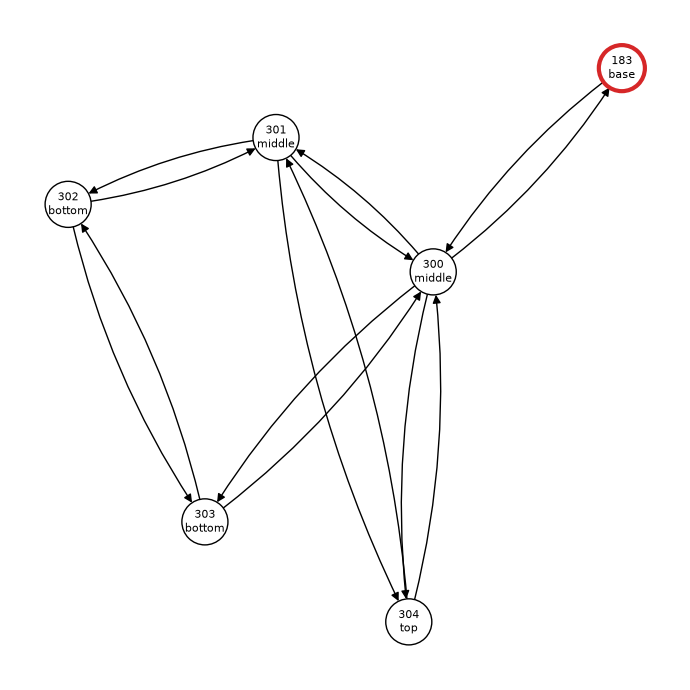

In [11]:
labels = [f"{i}\n{names[c]}" for i, c in enumerate(y)]
ei = np.asarray(graph.edge_index)
house = np.arange(300, 305)
touches_house = np.isin(ei[0], house) | np.isin(ei[1], house)
anchor = int(np.setdiff1d(ei[:, touches_house], house)[0])
print(f"the house hangs from base node {anchor}")

_ = visualize_graph(
    graph.edge_index[:, mx.array(np.nonzero(touches_house)[0])],
    node_labels=labels,
    highlight=anchor,
    backend="networkx",
)

## Train a GCN

The explainers mask edges by passing a weight for every edge to the model, so **the model must accept an `edge_weights` argument and forward it to its message passing layers**. `GCNConv` takes one, so we just pass it through. The model is called as `model(edge_index, node_features, edge_weights=None)`, the usual mlx-graphs argument order.

We use 3 GCN layers: a node of a house needs to see up to 3 hops away to recognize the whole house.

In [12]:
class GCN(nn.Module):
    # a GCN that forwards `edge_weights` to its layers, so its edges can be explained

    def __init__(self, in_dim, hidden, out_dim, num_layers=3, dropout=0.0):
        super().__init__()
        dims = [in_dim] + [hidden] * num_layers
        self.convs = [GCNConv(a, b) for a, b in zip(dims[:-1], dims[1:])]
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(hidden, out_dim)

    def __call__(self, edge_index, node_features, edge_weights=None):
        h = node_features
        for conv in self.convs:
            h = self.dropout(nn.relu(conv(edge_index, h, edge_weights)))
        return self.head(h)


def train(model, graph, train_idx, test_idx, epochs, lr=0.01):
    y = graph.node_labels

    def loss_fn(m):
        out = m(graph.edge_index, graph.node_features)
        return nn.losses.cross_entropy(out[train_idx], y[train_idx], reduction="mean")

    model.train()
    opt = optim.Adam(learning_rate=lr)
    step = nn.value_and_grad(model, loss_fn)
    for _ in range(epochs):
        loss, grads = step(model)
        opt.update(model, grads)
        mx.eval(model.parameters(), opt.state)

    model.eval()
    pred = mx.argmax(model(graph.edge_index, graph.node_features), axis=-1)
    acc = lambda idx: float((pred[idx] == y[idx]).astype(mx.float32).mean())  # noqa: E731
    print(f"loss={float(loss):.3f}  train acc={acc(train_idx):.3f}  test acc={acc(test_idx):.3f}")
    return pred

In [13]:
num_nodes = graph.num_nodes
perm = np.random.default_rng(0).permutation(num_nodes)
train_idx = mx.array(perm[: int(0.8 * num_nodes)])
test_idx = mx.array(perm[int(0.8 * num_nodes) :])

model = GCN(graph.node_features.shape[1], 20, 4)
start = time.perf_counter()
pred = train(model, graph, train_idx, test_idx, epochs=1000)
print(f"trained in {time.perf_counter() - start:.1f} s")

loss=0.185  train acc=0.961  test acc=0.979
trained in 2.4 s


## Explain one prediction

An `Explainer` puts together:

- the trained `model`,
- an `algorithm`, here `Saliency`, the simplest one: it scores each edge by how much the prediction reacts to a small change of that edge's weight (we compare it with the other algorithms below),
- `explanation_type="model"`: explain the class the model predicts. (`"phenomenon"` explains why the model gives the true label, passed as `target`.)
- what to mask: `edge_mask_type="object"` gives one score per edge. We do not mask nodes here (`node_mask_type=None`, the default): all the nodes have the same features, so the only information is in the edges. With a node mask as well, GNNExplainer can keep the prediction by dimming nodes instead of picking edges, and the edge mask then becomes unreliable. On Cora, where the features matter, we'll add a node mask.
- a `model_config` that describes the model's output: a multiclass node classifier that returns raw logits.

Calling the explainer with the graph and the `index` of a node returns an `Explanation`. We explain the roof of the first house, node 304.

In [14]:
model_config = dict(mode="multiclass_classification", task_level="node", return_type="raw")

explainer = Explainer(
    model=model,
    algorithm=Saliency(),
    explanation_type="model",
    edge_mask_type="object",
    model_config=model_config,
)
print(explainer)

node = int(np.nonzero(y == 3)[0][0])  # the first roof node
exp = explainer(graph.edge_index, graph.node_features, index=node)
print(exp)
print(f"node {node}: true class {names[y[node]]}, predicted {names[int(pred[node])]}")

Explainer(algorithm=Saliency(), explanation_type='model', node_mask_type=None, edge_mask_type='object')
Explanation(edge_mask=[4070], target=[700], prediction=[700, 4], index=304)
node 304: true class top, predicted top


`exp.edge_mask` holds one score per edge of the whole graph. Saliency scores are absolute gradients: they are not limited to $[0, 1]$, and only their relative sizes matter. Edges outside the node's 3-hop receptive field get a score of 0, since they cannot change its prediction. The masks are ordinary arrays, so we can list the most important edges and check them against the ground truth.

In [15]:
mask = np.asarray(exp.edge_mask)
print(f"edges with a non-zero score (receptive field): {int((mask > 0).sum())} of {mask.size}")
print("the 12 highest-scoring edges:")
for e in np.argsort(-mask)[:12]:
    s, d = ei[:, e]
    print(
        f"  {s:>3} ({names[y[s]]:>6}) -> {d:>3} ({names[y[d]]:>6})"
        f"   score {mask[e]:.3f}   in the house: {bool(truth[e])}"
    )

edges with a non-zero score (receptive field): 139 of 4070
the 12 highest-scoring edges:
  301 (middle) -> 304 (   top)   score 3.082   in the house: True
  300 (middle) -> 304 (   top)   score 2.112   in the house: True
  301 (middle) -> 300 (middle)   score 1.068   in the house: True
  183 (  base) -> 300 (middle)   score 0.984   in the house: False
  303 (bottom) -> 300 (middle)   score 0.979   in the house: True
  304 (   top) -> 300 (middle)   score 0.939   in the house: True
  300 (middle) -> 301 (middle)   score 0.816   in the house: True
  304 (   top) -> 301 (middle)   score 0.616   in the house: True
  302 (bottom) -> 301 (middle)   score 0.547   in the house: True
  302 (bottom) -> 303 (bottom)   score 0.150   in the house: True
  301 (middle) -> 302 (bottom)   score 0.148   in the house: True
  303 (bottom) -> 302 (bottom)   score 0.107   in the house: True


### Draw the explanation

`exp.visualize_graph()` draws the explanation: the darker an edge, the higher its score, and edges with a score of 0 are not drawn. The explained node is outlined in red. (With a node mask of type `"object"`, the nodes would also be shaded in blue by importance.) `edge_labels=True` writes each edge's score on it.

The receptive field of a node can hold hundreds of edges, so we first **threshold** the explanation to keep only the edges that matter. We keep the edges that score at least half as much as the best one: a cutoff relative to the top score adapts to each explanation, while a fixed number of edges (e.g. the top 12) would also draw near-zero edges when only a few matter. `threshold()` returns a new `Explanation` and leaves the original unchanged.

Without a `path`, the figure is shown inline. Pass a path, e.g. `exp.visualize_graph("explanation.png")`, to save it to a file instead. If the `graphviz` package and program are installed, it is used by default; we pick the networkx backend so the figures look the same everywhere.

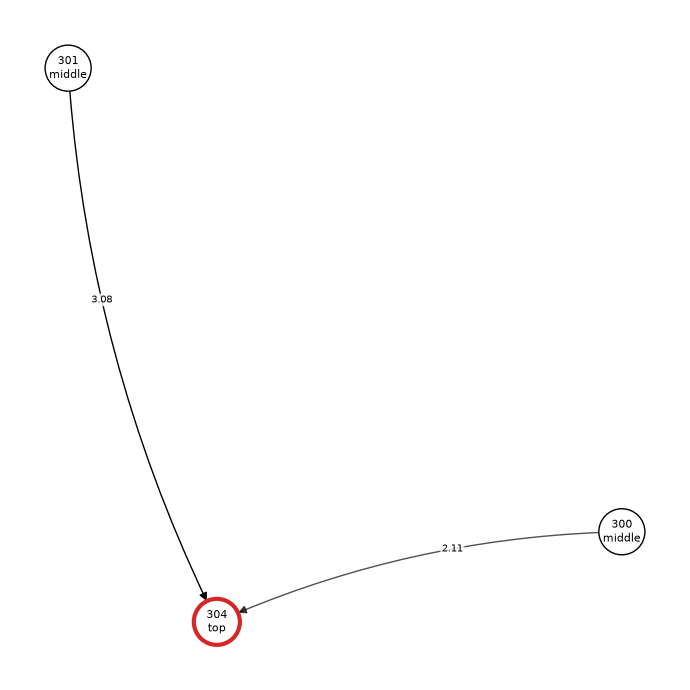

In [16]:
# keep the edges that score at least half as much as the best one
cutoff = 0.5 * float(exp.edge_mask.max())
_ = exp.threshold("hard", cutoff).visualize_graph(
    backend="networkx", node_labels=labels, edge_labels=True
)

All the drawn edges belong to the house, and the two strongest are the edges into the roof node: the messages that tell the model it sits on top of two middle nodes.

There are three kinds of thresholds:

| Call | Keeps |
|---|---|
| `threshold("hard", 0.1)` | the scores above 0.1, set the others to 0 |
| `threshold("topk", 12)` | the 12 highest scores, set the others to 0 |
| `threshold("topk_hard", 12)` | 1 for the 12 highest scores, 0 for the others |

`topk_hard` turns the explanation into a subgraph, which is what the fidelity metrics below need. `get_explanation_subgraph()` returns the `edge_index` of the edges with a non-zero score, and `get_complement_subgraph()` the others.

In [17]:
top = float(exp.edge_mask.max())
for args in [("hard", 0.25 * top), ("hard", 0.5 * top), ("topk", 12), ("topk_hard", 12)]:
    kept = exp.threshold(*args).get_explanation_subgraph()
    print(f"threshold({args[0]!r}, {args[1]:.3g}): {kept.shape[1]} edges kept")

threshold('hard', 0.77): 7 edges kept
threshold('hard', 1.54): 2 edges kept
threshold('topk', 12): 12 edges kept
threshold('topk_hard', 12): 12 edges kept


## Compare the algorithms

The three algorithms get at importance in different ways:

- **Saliency** takes the gradient of the predicted class's score with respect to every edge weight. It needs one backward pass, so it is the fastest, but a gradient only says what happens for a tiny change of the edge weight.
- **IntegratedGradients** averages these gradients along a path from an empty graph (all edge weights 0) to the real one (all 1), in `n_steps` steps, and multiplies by the change of weight. The attributions add up to the change of score between the two graphs. `absolute=True` returns their absolute values, since edges that push against the prediction matter too.
- **GNNExplainer** learns a soft mask by gradient descent: the masked graph must keep the prediction, while the mask is pushed to be small and close to 0 or 1.

We give the three algorithms the same node, mask only edges, and draw the 12 highest-scoring edges of each.

Saliency: 11 of its 12 top edges are house edges


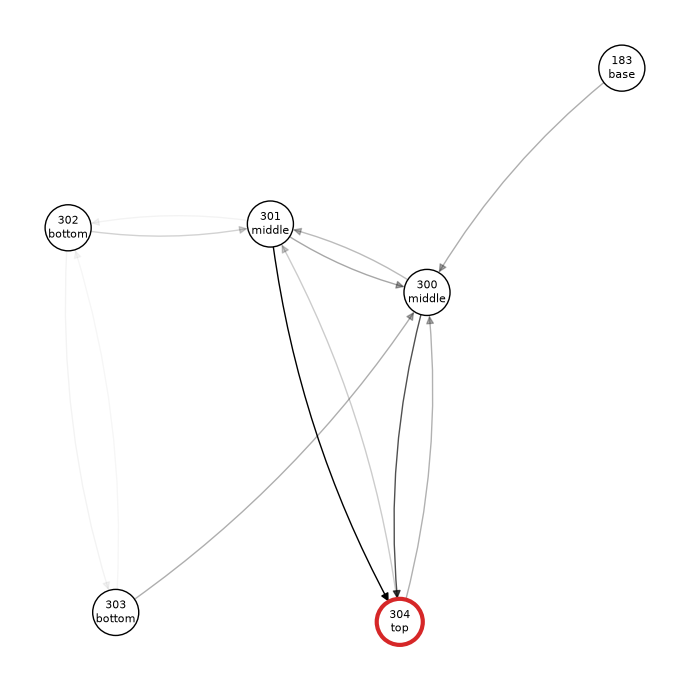

IntegratedGradients: 12 of its 12 top edges are house edges


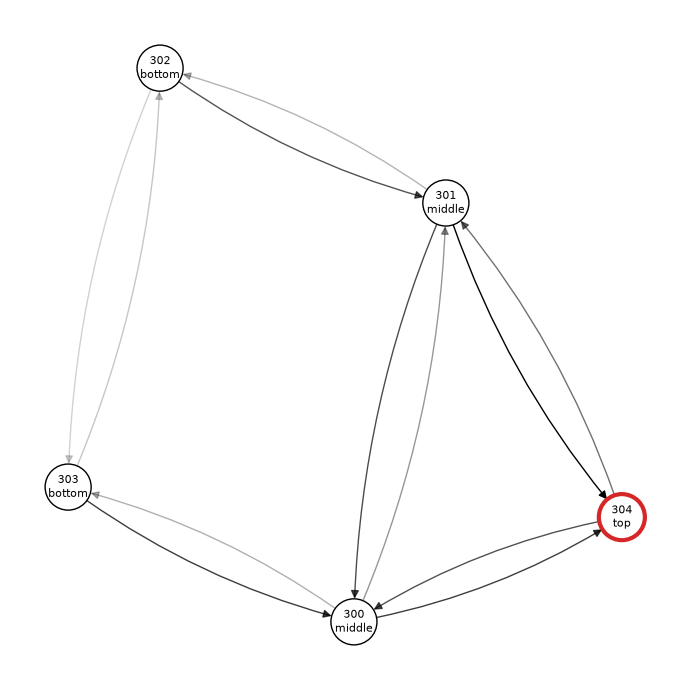

GNNExplainer: 10 of its 12 top edges are house edges


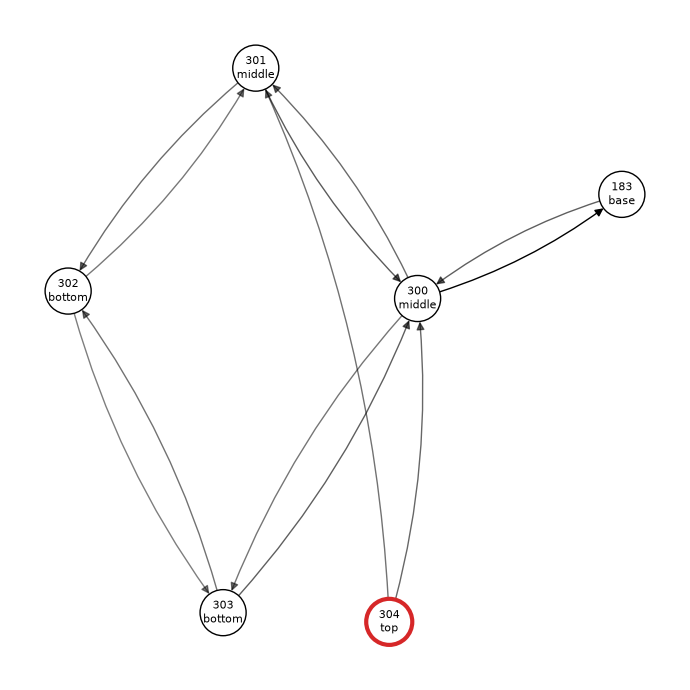

In [18]:
algorithms = {
    "Saliency": Saliency(),
    "IntegratedGradients": IntegratedGradients(n_steps=50, absolute=True),
    "GNNExplainer": GNNExplainer(epochs=200, lr=0.01, seed=0),
}
explainers = {
    name: Explainer(
        model=model,
        algorithm=algorithm,
        explanation_type="model",
        edge_mask_type="object",
        model_config=model_config,
    )
    for name, algorithm in algorithms.items()
}

for name, ex in explainers.items():
    e = ex(graph.edge_index, graph.node_features, index=node)
    top = np.argsort(-np.asarray(e.edge_mask))[:12]
    print(f"{name}: {int(truth[top].sum())} of its 12 top edges are house edges")
    _ = e.threshold("topk", 12).visualize_graph(backend="networkx", node_labels=labels)

## Measure the quality of explanations

One drawing is not enough to compare methods. We score each of them on 20 nodes inside houses with three measures:

- **Ground-truth AUC** (`groundtruth_auc`): how well the scores rank house edges above the other edges, as a ROC AUC (1 is a perfect ranking, 0.5 is random). It needs the true explanation, so it only exists on synthetic benchmarks. As in the GNNExplainer paper, we compute it over the edges of the node's 3-hop receptive field.
- **Fidelity+**: how often the prediction changes when the explanation is *removed* from the graph. A good explanation holds what the model needs, so removing it should change the prediction: higher is better.
- **Fidelity−**: how often the prediction changes when *only* the explanation is kept. A good explanation is enough on its own: lower is better.
- The **characterization score** combines the two into one number (a weighted harmonic mean of fidelity+ and 1 − fidelity−): higher is better.

Fidelity needs a hard subgraph, so we keep the 12 top edges, the size of a house, with `threshold("topk_hard", 12)`.

In [19]:
motif_nodes = np.nonzero(y > 0)[0]
nodes = motif_nodes[:: max(1, len(motif_nodes) // 20)][:20]

print(f"{'algorithm':20s} {'AUC':>6} {'fid+':>6} {'fid-':>6} {'charact.':>9} {'ms/node':>8}")
for name, ex in explainers.items():
    aucs, fid_pos, fid_neg = [], [], []
    start = time.perf_counter()
    for n in nodes:
        e = ex(graph.edge_index, graph.node_features, index=int(n))
        _, _, _, in_field = k_hop_subgraph(int(n), 3, graph.edge_index, num_nodes=num_nodes)
        keep = mx.array(np.nonzero(np.asarray(in_field))[0])
        auc = groundtruth_auc(e.edge_mask[keep], graph.edge_groundtruth[keep])
        if auc is not None:
            aucs.append(auc)
        pos, neg = fidelity(ex, e.threshold("topk_hard", 12))
        fid_pos.append(pos)
        fid_neg.append(neg)
    ms = (time.perf_counter() - start) / len(nodes) * 1000
    fp, fn = float(np.mean(fid_pos)), float(np.mean(fid_neg))
    print(
        f"{name:20s} {np.mean(aucs):6.3f} {fp:6.2f} {fn:6.2f}"
        f" {characterization_score(fp, fn):9.2f} {ms:8.0f}"
    )

algorithm               AUC   fid+   fid-  charact.  ms/node
Saliency              0.994   0.50   0.50      0.50        9
IntegratedGradients   0.994   0.30   0.70      0.30      146
GNNExplainer          0.891   0.90   0.00      0.95      595


The AUC tells us whether a method points at the right edges; fidelity tells us whether those edges actually drive the model. They need not agree: a model can rely on a shortcut, and then a faithful explanation does not match the ground truth. The time per node shows the cost of each method: Saliency needs one backward pass, IntegratedGradients `n_steps` of them, and GNNExplainer `epochs` optimization steps.

The same loop is in [`examples/explain_ba_shapes.py`](https://github.com/mlx-graphs/mlx-graphs/blob/main/examples/explain_ba_shapes.py).

## Feature importance on Cora

On BA-Shapes only the structure matters. On real graphs, the node features carry much of the information, and we want to know which of them a prediction relies on. Cora is a citation graph of 2,708 papers, each described by a bag-of-words vector over 1,433 words and labeled with one of 7 topics. We train a 2-layer GCN on the public split.

In [20]:
cora = PlanetoidDataset("cora")[0]
print(cora)

cora_train = mx.array(np.nonzero(np.asarray(cora.train_mask))[0])
cora_test = mx.array(np.nonzero(np.asarray(cora.test_mask))[0])
cora_model = GCN(cora.node_features.shape[1], 16, 7, num_layers=2, dropout=0.5)
cora_pred = train(cora_model, cora, cora_train, cora_test, epochs=200)

Loading cora data ... Done
GraphData(
	edge_index(shape=(2, 10556), int32)
	node_features(shape=(2708, 1433), float32)
	node_labels(shape=(2708,), int32)
	train_mask(shape=(2708,), bool)
	val_mask(shape=(2708,), bool)
	test_mask(shape=(2708,), bool))
loss=0.195  train acc=1.000  test acc=0.765


To get one score per node feature, we set `node_mask_type="attributes"`. GNNExplainer then learns a mask of the same shape as the features, `[2708, 1433]`, together with the edge mask. We explain a test paper that the model classifies correctly.

`visualize_feature_importance` sums the mask over all nodes and plots the `top_k` features with the highest totals.

Explanation(node_mask=[2708, 1433], edge_mask=[10556], target=[2708], prediction=[2708, 7], index=1709)
paper 1709: true topic 2, predicted 2


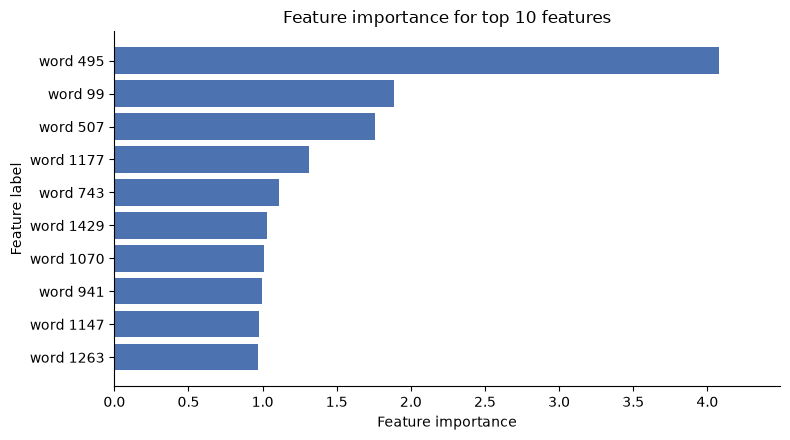

In [21]:
cora_y = np.asarray(cora.node_labels)
test_nodes = np.asarray(cora_test)
correct = test_nodes[np.asarray(cora_pred)[test_nodes] == cora_y[test_nodes]]
paper = int(correct[0])

cora_explainer = Explainer(
    model=cora_model,
    algorithm=GNNExplainer(epochs=200, lr=0.01, seed=0),
    explanation_type="model",
    node_mask_type="attributes",
    edge_mask_type="object",
    model_config=model_config,
)
cora_exp = cora_explainer(cora.edge_index, cora.node_features, index=paper)
print(cora_exp)
print(f"paper {paper}: true topic {cora_y[paper]}, predicted {int(cora_pred[paper])}")

_ = cora_exp.visualize_feature_importance(
    top_k=10, feat_labels=[f"word {i}" for i in range(cora.node_features.shape[1])]
)

Cora ships without its vocabulary, so the features are word indices rather than words. With your own data, pass the feature names as `feat_labels`. Words absent from a paper (a feature of 0) cannot affect the prediction, so their scores stay at 0.

The same `Explanation` also holds an edge mask, which shows the papers whose citations matter for this prediction. We label each paper with its topic: a paper's neighbors often share its topic, and the model learns to use that.

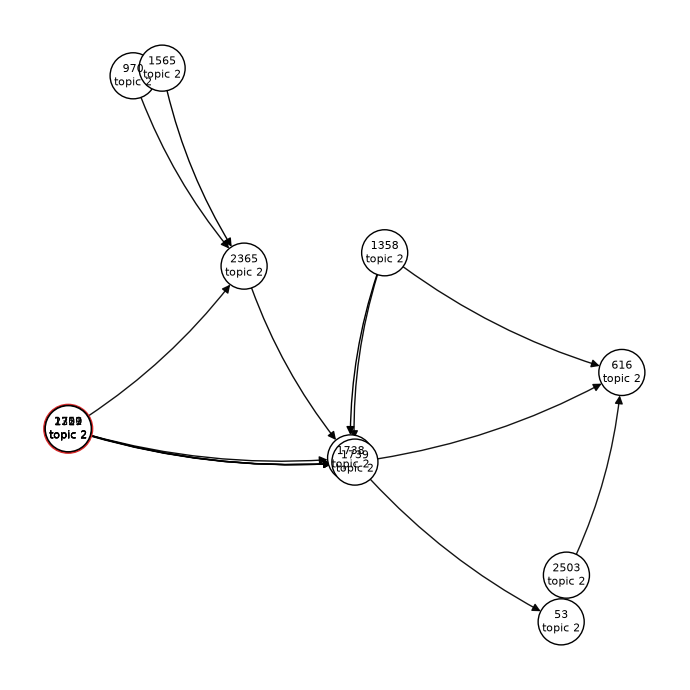

In [22]:
cora_labels = [f"{i}\ntopic {c}" for i, c in enumerate(cora_y)]
_ = cora_exp.threshold("topk", 15).visualize_graph(backend="networkx", node_labels=cora_labels)

For a single importance score per feature shared by all nodes, use `node_mask_type="common_attributes"` (a `[1, 1433]` mask). Saliency and IntegratedGradients support all the mask types too.

## Summary

- Wrap a trained model in an `Explainer` with an algorithm (`GNNExplainer`, `Saliency` or `IntegratedGradients`), the masks you want and a `model_config`; the model must accept and forward `edge_weights` to explain edges.
- Calling the explainer with `index=` returns an `Explanation` with an `edge_mask` and/or a `node_mask`.
- Threshold it with `threshold("hard" | "topk" | "topk_hard", value)`, draw it with `visualize_graph()` and `visualize_feature_importance()`, or read the masks directly.
- Score explanations with `fidelity` and `characterization_score`, and with `groundtruth_auc` when the true explanation is known.

Graph-level models are explained the same way, with `task_level="graph"` in the `model_config` and no `index`. See the [`explain` API reference](../../api/explain/index.md) for all the options.